<a href="https://colab.research.google.com/github/<org>/<repo>/blob/main/solutions/02_sbi_double_well_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SBI for time series: Brownian motion in a double well

**AlgoSB 2026 · simulation-based inference · hands-on notebook 2 of 2 · 75 minutes**

Notebook 1 had an answer key. This one does not. A particle diffuses in a double-well potential, you see its position over time, and you want two numbers: the **height of the barrier** between the wells and the **diffusion coefficient**. This is the model behind the force-spectroscopy example of this morning's lecture, without the linker: you observe the particle position directly.

The simulator is given. Your work is to decide **what to measure on a trajectory**, and to find out what those measurements can and cannot tell you.

| Part | Min | Your challenge |
| --- | --- | --- |
| 0 | 5 | Recap and setup |
| 1 | 10 | Inference by hand |
| 2 | 33 | Invent your summary statistics |
| 3 | 12 | Catch the blind trajectory |
| 4 | 15 | A posterior that is blind to D |

The rules are those of Notebook 1: every part is a challenge, a check cell prints ✅ PASS or ❌ NOT YET, how you get there is up to you, and after a pass you write one sentence on why it worked. Worked answers are in `solutions/`.

> **Solutions notebook.** Same notebook as the students', with every challenge solved. Each answer comes with the reasoning and with the message the part is meant to carry.

In [1]:
# Setup. On Colab this installs sbi and fetches the tutorial files; on your own machine it only
# steps up from solutions/ to the folder that holds tutorial_utils.py.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("tutorial_utils.py"):
    !pip install -q sbi==0.27.0
    !git clone -q --depth 1 https://github.com/<org>/<repo>.git
    %cd <repo>
elif not os.path.exists("tutorial_utils.py"):
    os.chdir("..")

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch

import sbi
from sbi.analysis import pairplot
from sbi.inference import NPE
from sbi.utils import BoxUniform

import tutorial_utils as tu
from tutorial_utils import (check_blind, check_blind_to_D, check_practice, check_score,
                            plot_posteriors, plot_trajectories, posterior_widths, summarize,
                            train_and_score)

warnings.filterwarnings("ignore")  # sbi is talkative; none of its warnings matter today
tu.set_plot_style()
torch.manual_seed(0)
np.random.seed(0)
print(f"sbi {sbi.__version__} · torch {torch.__version__}")

sbi 0.27.0 · torch 2.15.0+cu132


## Part 0 · Recap and setup (5 min)

The five steps are the same as in Notebook 1, with the same names. Only the data got harder.

| Step | In the code | Notebook 1 | This notebook |
| --- | --- | --- | --- |
| 1. Prior | `prior` | box for a 2D mean | box for barrier height and diffusion coefficient |
| 2. Simulator | `simulator(theta)` returns `x` | one noisy 2D point | one trajectory of 5,000 positions |
| 3. Training set | `theta`, `x` | 2D points | trajectories, reduced to **summary statistics** |
| 4. Training | `posterior` | NPE | NPE |
| 5. Inference and checks | `x_o`, `samples` | compare with the answer key | a blind trajectory, and no answer key |

**The model.** A particle at position $x$ feels the double-well potential

$$G_0(x) = \Delta G^{\ddagger}\, f(x/x^{\ddagger}), \qquad f(u) = \begin{cases} 1 - 2u^2, & |u| \le 1/2 \\ 2(|u|-1)^2, & |u| > 1/2 \end{cases}$$

with wells at $x = \pm x^{\ddagger}$ and a barrier of height $\Delta G^{\ddagger}$ at $x = 0$. It moves by overdamped Brownian dynamics with diffusion coefficient $D$:

$$x(t+\Delta t) = x(t) - D\,\partial_x G_0(x)\,\Delta t + \sqrt{2 D\,\Delta t}\;\xi(t), \qquad \xi \sim \mathcal{N}(0, 1).$$

Units: $k_BT = 1$ and $x^{\ddagger} = 1$. The two parameters to infer are $\theta = (\Delta G^{\ddagger},\ \log_{10} D)$.

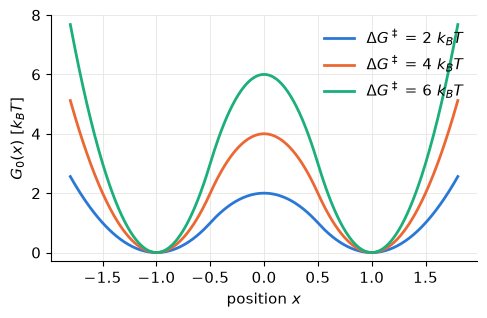

In [3]:
# 1. Prior: barrier height between 2 and 6 k_BT, diffusion coefficient between 0.1 and 1
prior = BoxUniform(low=torch.tensor([2.0, -1.0]), high=torch.tensor([6.0, 0.0]))

LIMITS = [[2, 6], [-1, 0]]
LABELS = tu.DW_LABELS

# The potential for three barrier heights
grid = np.linspace(-1.8, 1.8, 400)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for dG, color in zip((2, 4, 6), (tu.C_YOURS, tu.C_KEY, tu.C_OTHER)):
    ax.plot(grid, tu.double_well_potential(grid, dG), lw=2, color=color, label=rf"$\Delta G^\ddagger$ = {dG} $k_BT$")
ax.set(xlabel="position $x$", ylabel=r"$G_0(x)$ [$k_BT$]", ylim=(-0.3, 8))
ax.legend();

## Part 1 · Inference by hand (10 min)

Here is the simulator. Read it together: it is the Langevin equation above, integrated with a time step of 0.002. Every 50th step is saved, which gives 5,000 frames, 0.1 time units apart.

In [4]:
DT, STRIDE, N_FRAMES = 0.002, 50, 5000

def force(x, dG):
    """Force -dG_0/dx: a harmonic barrier for |x| <= 1/2, matched to harmonic wells at x = ±1."""
    return -dG * np.where(np.abs(x) <= 0.5, -4 * x, 4 * (x - np.sign(x)))

# 2. Simulator
def simulator(theta, seed=None):
    """Brownian dynamics in the double well, one trajectory per row of theta.

    theta: shape (n, 2), columns barrier height [k_BT] and log10 D
    returns x: positions, shape (n, 5000)
    """
    theta = np.atleast_2d(np.asarray(theta, dtype=np.float32))
    dG, D = theta[:, 0], 10 ** theta[:, 1]
    rng = np.random.default_rng(seed)
    drift = D * DT                                        # D Δt, multiplies the force
    kick = np.sqrt(2 * D * DT)                            # size of one random kick
    x_t = np.full(len(theta), -1.0, dtype=np.float32)     # every trajectory starts in the left well
    x = np.empty((len(theta), N_FRAMES), dtype=np.float32)
    for frame in range(N_FRAMES):
        xi = rng.standard_normal((STRIDE, len(theta)), dtype=np.float32)
        for step in range(STRIDE):
            x_t = x_t + drift * force(x_t, dG) + kick * xi[step]
        x[:, frame] = x_t
    return torch.from_numpy(x)

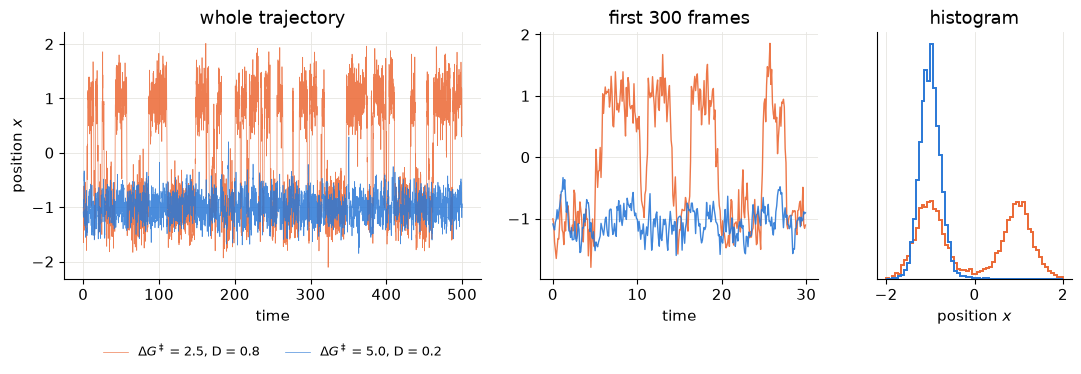

In [5]:
# Two parameter sets, two trajectories. Each plot shows the whole trajectory, its first frames, and its histogram.
x_demo = simulator(torch.tensor([[2.5, np.log10(0.8)], [5.0, np.log10(0.2)]]), seed=1)
plot_trajectories(x_demo, [r"$\Delta G^\ddagger$ = 2.5, D = 0.8", r"$\Delta G^\ddagger$ = 5.0, D = 0.2"]);

Now the inverse problem. Somebody simulated the **practice trajectory** below and did not tell you the parameters.

**Challenge.** Find its $\Delta G^{\ddagger}$ and $D$ by trial and error: simulate, compare, adjust.

**Passes when** your last try is within 0.5 $k_BT$ of the hidden barrier height and within a factor of 1.5 of the hidden diffusion coefficient, in at most ten tries.

In [6]:
x_practice = tu.load_trajectory("practice")

tries = []        # every try is recorded here; run this cell again to start over

def try_parameters(dG, D):
    """Simulate one trajectory at (dG, D) and show it next to the practice trajectory."""
    tries.append((dG, D))
    x_try = simulator(torch.tensor([[dG, np.log10(D)]]), seed=1000 + len(tries))[0]
    plot_trajectories([x_practice, x_try],
                      ["practice trajectory", rf"try {len(tries)}: $\Delta G^\ddagger$ = {dG}, D = {D}"])
    return x_try

In [7]:
# Before the first try, read the barrier height off the histogram of the practice trajectory.
#
# In equilibrium the particle visits x with probability proportional to exp(-G_0(x)), whatever D is.
# So the share of frames it spends in the barrier region |x| < 0.5 depends on the barrier height alone.
# Compute that share for a range of barrier heights and pick the one that matches.
grid = np.linspace(-3, 3, 6001)

def barrier_share(dG):
    boltzmann = np.exp(-tu.double_well_potential(grid, dG))
    return boltzmann[np.abs(grid) < 0.5].sum() / boltzmann.sum()

share_practice = (x_practice.abs() < 0.5).float().mean().item()
candidates = np.arange(2.0, 6.01, 0.1)
dG_guess = candidates[np.argmin([abs(barrier_share(c) - share_practice) for c in candidates])]
print(f"{share_practice:.1%} of the frames are in the barrier region  ->  barrier height ≈ {dG_guess:.1f} k_BT")

4.8% of the frames are in the barrier region  ->  barrier height ≈ 3.4 k_BT


frame-to-frame roughness: practice 0.285, this try 0.229


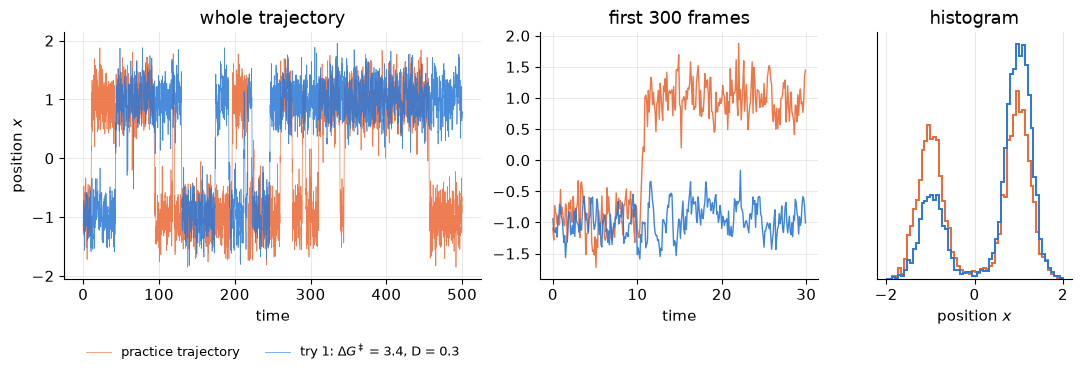

In [8]:
# Try 1: that barrier height, and a diffusion coefficient from the middle of the prior.
def roughness(x):
    """How far the particle moves from one frame to the next."""
    return (x[1:] - x[:-1]).std().item()

D_guess = 0.3
x_try = try_parameters(dG=round(float(dG_guess), 1), D=D_guess)
print(f"frame-to-frame roughness: practice {roughness(x_practice):.3f}, this try {roughness(x_try):.3f}")

frame-to-frame roughness: practice 0.285, this try 0.264


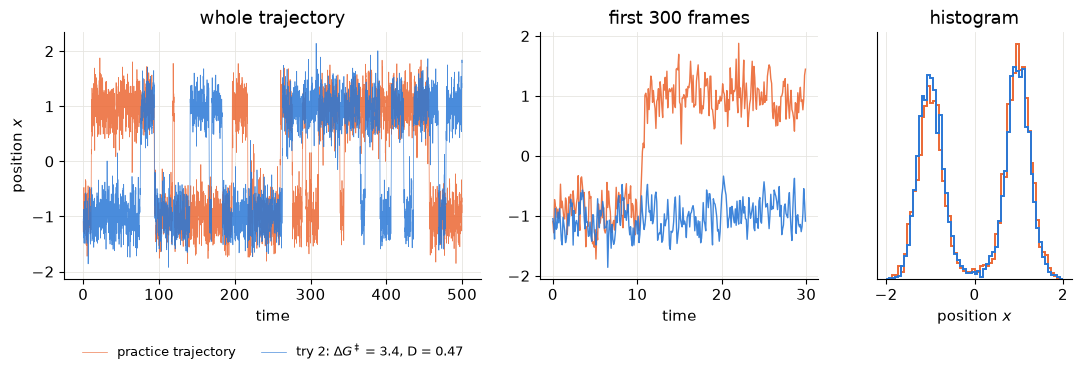

In [9]:
# Try 2: the histograms agree, so the barrier stays. But the practice trajectory is rougher in the
# zoom and hops more often: its D is larger. For free diffusion the squared displacement grows in
# proportion to D, so scale D by the squared ratio of the two roughness values.
D_guess = round(D_guess * (roughness(x_practice) / roughness(x_try)) ** 2, 2)
x_try = try_parameters(dG=round(float(dG_guess), 1), D=D_guess)
print(f"frame-to-frame roughness: practice {roughness(x_practice):.3f}, this try {roughness(x_try):.3f}")

In [10]:
check_practice(tries)

✅ PASS · Part 1 · by hand · try 2 of at most 10: within 0.5 k_BT for the barrier height and a factor 1.5 for D


**Why it works.** Three things can be read off a trajectory.

- *The histogram* (right panel) is the Boltzmann distribution $e^{-G_0(x)}$. It depends on the barrier height and not on $D$: narrower wells and a deeper dip at $x = 0$ mean a higher barrier.
- *The short-time roughness* (middle panel) depends mostly on $D$: a larger $D$ makes larger jumps from frame to frame.
- *The number of hops* (left panel) depends on both: the hop rate is proportional to $D\,\Delta G^{\ddagger}e^{-\Delta G^{\ddagger}}$ (Kramers' formula for this potential).

So the hop count alone cannot separate the two parameters. One more $k_BT$ of barrier and a $D$ about twice as large give the same hop rate. The histogram breaks the tie.

By eye this takes a handful of tries; with two numbers read off the trajectory it takes two. The roughness is the better guide to $D$ than the hop count: a trajectory has 5,000 displacements but only a dozen hops, so the hop count of a single trajectory is uncertain by about its square root. The correction of try 2 is still a little too small, because within one frame the particle already feels the walls of its well. A third try would close the gap. Part 4 comes back to this.

**Message of Part 1.** Both parameters change how often the particle hops, so the hop frequency alone cannot separate them. Something else in the trajectory has to.

## Part 2 · Invent your summary statistics (33 min)

What you just did by eye, a network should now do: map a trajectory to the parameters behind it. But a trajectory is 5,000 numbers, and you have time for 2,000 simulations. So each trajectory is first reduced to a handful of numbers, its **summary statistics**, and the network is trained on those. The network cannot use information the summaries threw away.

First, the training set. This is step 3 of the recipe, simulated live:

In [11]:
# 3. Training set: 2,000 parameters from the prior, one trajectory each (about 10 seconds)
torch.manual_seed(0)
theta = prior.sample((2000,))
x = simulator(theta, seed=0)
print("theta:", tuple(theta.shape), "  x:", tuple(x.shape))

theta: (2000, 2)   x: (2000, 5000)


A summary function takes a batch of trajectories and returns one row of numbers per trajectory. Here is the simplest one you could think of, as a baseline: the mean and the standard deviation of $x$.

In [12]:
def summary_baseline(x):
    """x: NumPy array of shape (n_trajectories, 5000). Returns shape (n_trajectories, n_statistics)."""
    return np.stack([
        x.mean(axis=1),
        x.std(axis=1),
    ], axis=1)

print(summarize(summary_baseline, x[:3]))

tensor([[-0.2835,  0.9789],
        [ 0.2226,  1.0201],
        [ 0.2925,  0.9950]])


The helper `train_and_score` runs steps 3 and 4 exactly as in Notebook 1 and adds a score. Its core is:

```python
s = summarize(summary, x)                           # your statistics, for all 2,000 trajectories
inference = NPE(prior=prior, density_estimator=...) # a small neural spline flow
inference.append_simulations(theta, s).train()
posterior = inference.build_posterior()
score = posterior.log_prob(theta_test, x=s_test).mean()
```

**The score** is the average log posterior density at the true parameters, over a common test set of 200 trajectories that nobody trains on. Higher is better. It rewards posteriors that are narrow and in the right place, and it punishes overconfident ones. A posterior that learned nothing and returns the prior scores −1.39.

`posterior_widths` adds a second view: how wide the 90% interval of each parameter is, as a fraction of the prior's, on average over the test set.

In [13]:
posterior_baseline, score_baseline = train_and_score(summary_baseline, theta, x)
posterior_widths(posterior_baseline, summary_baseline)
check_score(score_baseline)

score = -1.13   (2 statistics, 2,000 simulations, 125 epochs)
90% interval, as a fraction of the prior's: ΔG‡ 77%, log D 95%
❌ NOT YET · Part 2 · summary statistics · score -1.13: no medal yet (bronze > -1.08, silver ≥ 3.38, gold > 3.58)


The baseline barely beats the prior.

**Challenge.** Reduce the 5,000 frames to a handful of numbers that carry what a trajectory says about $\Delta G^{\ddagger}$ and $D$. Train, read the score, improve. There is no list of statistics to choose from and no hint: you know what you looked at in Part 1.

**Passes when**
- 🥉 bronze: you beat the baseline,
- 🥈 silver: you reach the score of our reference solution,
- 🥇 gold: you beat it.

Retraining the same statistics with another `seed` moves the score by about ±0.05, so differences smaller than that mean nothing.

### A worked path to silver

The three observations of Part 1, turned into numbers. Each step is scored, so you can see what each group of statistics buys.

**Step 1: the histogram.** The histogram is symmetric under $x \to -x$, and which well the particle happens to sit in says nothing about the potential. So we describe the histogram of $|x|$: how much of the time the particle spends in the barrier region, and where and how wide the well is.

In [14]:
from scipy import stats

def summary_static(x):
    """Four numbers from the histogram of |x|. None of them needs the time order."""
    a = np.abs(x)
    return np.stack([
        (a < 0.5).mean(axis=1),          # barrier occupancy: share of frames in the barrier region
        a.mean(axis=1),                  # where the well is
        a.std(axis=1),                   # how wide it is
        stats.kurtosis(a, axis=1),       # how heavy the tail towards the barrier is
    ], axis=1)

posterior_static, score_static = train_and_score(summary_static, theta, x)
posterior_widths(posterior_static, summary_static);

score = 0.74   (4 statistics, 2,000 simulations, 79 epochs)
90% interval, as a fraction of the prior's: ΔG‡ 13%, log D 95%


The barrier height is pinned to about an eighth of its prior range. The diffusion coefficient is where the prior left it. Part 4 comes back to this.

**Step 2: the time order.** Two kinds of dynamic statistics: how far the particle moves within 1, 10 and 100 frames, and how often it hops between the wells.

In [15]:
def count_hops(x, threshold=0.5):
    """Number of well-to-well transitions per trajectory.

    The particle is "in a well" once it is beyond ±threshold, and stays assigned to that well
    until it arrives in the other one. Wiggling across x = 0 on top of the barrier does not count.
    """
    side = np.sign(x) * (np.abs(x) > threshold)                       # -1, 0 (barrier region), +1
    last = np.where(side != 0, np.arange(x.shape[1])[None], 0)
    last = np.maximum.accumulate(last, axis=1)                        # index of the last frame in a well
    well = np.take_along_axis(side, last, axis=1)
    well[well == 0] = -1                                              # every trajectory starts on the left
    return (np.diff(well, axis=1) != 0).sum(axis=1)

def summary_dynamic(x):
    """Four numbers that need the time order."""
    return np.stack([
        (x[:, 1:] - x[:, :-1]).std(axis=1),          # displacement over 1 frame
        (x[:, 10:] - x[:, :-10]).std(axis=1),        # over 10 frames
        (x[:, 100:] - x[:, :-100]).std(axis=1),      # over 100 frames
        count_hops(x),
    ], axis=1)

posterior_dynamic, score_dynamic = train_and_score(summary_dynamic, theta, x)
posterior_widths(posterior_dynamic, summary_dynamic);

score = 2.99   (4 statistics, 2,000 simulations, 145 epochs)
90% interval, as a fraction of the prior's: ΔG‡ 21%, log D 6%


The dynamic statistics pin $D$ to a twentieth of its prior range. They also know something about the barrier, because the hop count depends on both parameters.

**Step 3: both together.** This is our reference solution: eight numbers.

In [16]:
def my_summary(x):
    return np.concatenate([summary_static(x), summary_dynamic(x)], axis=1)

posterior, score = train_and_score(my_summary, theta, x)
posterior_widths(posterior, my_summary)
check_score(score)

score = 3.54   (8 statistics, 2,000 simulations, 141 epochs)
90% interval, as a fraction of the prior's: ΔG‡ 12%, log D 5%
✅ PASS · Part 2 · summary statistics · score 3.54: 🥈 silver (bronze > -1.08, silver ≥ 3.38, gold > 3.58)


### One way to gold

Ask what the likelihood would need, if you could write it down. Two ideas, both from the physics of the model.

- *Solve for the parameters.* Inside a well the particle is an Ornstein-Uhlenbeck process: its position has variance $1/(4\Delta G^{\ddagger})$ and its fluctuations decay at the rate $4\Delta G^{\ddagger} D$. So the variance in the well gives an estimate of $\Delta G^{\ddagger}$, and the frame-to-frame correlation in the well then gives an estimate of $D$. The network only has to correct these estimates, not discover them.
- *Use the sufficient statistics of an approximate likelihood.* For one step of the Langevin equation, the log-likelihood of a path is a sum over frames that contains the data only through three averages: $\langle F\,\Delta x\rangle$, $\langle F^2\rangle$ and $\langle \Delta x^2\rangle$, where $F(x)$ is the force per unit barrier height. The frames here are 50 steps apart, so this is only an approximation, but the three averages still carry most of what the dynamics know.

In [17]:
FRAME_TIME = DT * STRIDE

def summary_gold(x):
    a = np.abs(x)
    y, in_well = a - 1, a > 0.5

    # estimators that solve for the parameters
    var_well = (y**2 * in_well).sum(axis=1) / in_well.sum(axis=1)
    dG_estimate = 1 / (4 * var_well)                                    # variance in the well = 1 / (4 dG)
    pairs = in_well[:, 1:] & in_well[:, :-1]
    correlation = (y[:, 1:] * y[:, :-1] * pairs).sum(axis=1) / pairs.sum(axis=1) / var_well
    correlation = np.clip(correlation, 1e-3, 0.999)
    D_estimate = -np.log(correlation) / (4 * dG_estimate * FRAME_TIME)  # decay rate = 4 dG D
    hop_rate = (count_hops(x) + 0.5) / (x.shape[1] * FRAME_TIME)
    barrier = (a < 0.5).mean(axis=1) + 1e-4

    # sufficient statistics of the one-step likelihood
    F = force(x[:, :-1], 1.0)
    dx = x[:, 1:] - x[:, :-1]
    F_dx, F_F, dx_dx = (F * dx).mean(axis=1), (F**2).mean(axis=1), (dx**2).mean(axis=1)

    return np.stack([np.log(dG_estimate), np.log(D_estimate), np.log(hop_rate), np.log(barrier),
                     F_dx, np.log(F_F), np.log(dx_dx), F_dx / F_F], axis=1)

posterior_gold, score_gold = train_and_score(summary_gold, theta, x)
posterior_widths(posterior_gold, summary_gold)
check_score(score_gold)

score = 3.67   (8 statistics, 2,000 simulations, 166 epochs)
90% interval, as a fraction of the prior's: ΔG‡ 11%, log D 4%
✅ PASS · Part 2 · summary statistics · score 3.67: 🥇 gold (bronze > -1.08, silver ≥ 3.38, gold > 3.58)


### The three questions

In [18]:
# Question 2: does adding statistics always help? Ten columns of pure noise.
def summary_with_noise(x):
    noise = np.random.default_rng(0).normal(size=(len(x), 10))
    return np.concatenate([my_summary(x), noise], axis=1)

_, score_noise = train_and_score(summary_with_noise, theta, x)
print(f"\nreference statistics: {score:.2f}    with ten noise columns: {score_noise:.2f}")

score = 3.01   (18 statistics, 2,000 simulations, 117 epochs)

reference statistics: 3.54    with ten noise columns: 3.01


1. **Which statistics moved the score most?** From the baseline (about −1.2) the static group lifts the score to about 0.7 and the dynamic group to about 2.9; together they reach about 3.5. The dynamic statistics move it most, because they are the only ones that know $D$, and through the hop count they know the barrier too. The static ones then sharpen the barrier height by another factor of two.
2. **Does adding statistics always help?** No. Noise columns carry no information, and the network has to learn to ignore them from 2,000 examples. The score drops. Every statistic costs training data; it has to pay for itself with information.
3. **Same score, different statistics?** Then the two sets carry the same information about the parameters. Many different summaries are equally good: what matters is not the list, but what it preserves. In the limit, a set of statistics that preserves everything the data say about θ is called *sufficient*.

**Message of Part 2.** The network cannot use information the summaries threw away, so choosing them is where the physics enters. A score on held-out simulations replaces intuition.

## Part 3 · Catch the blind trajectory (12 min)

This is the trajectory the afternoon is about. Its parameters are hidden; they are revealed at the end of the notebook.

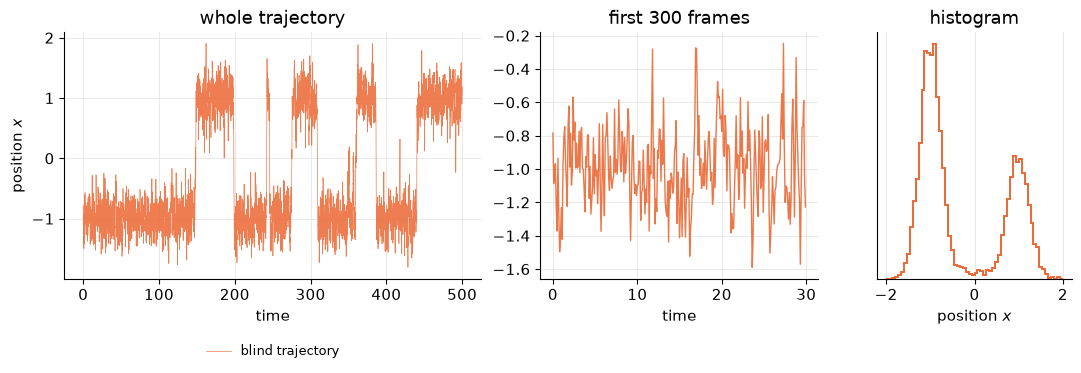

In [19]:
x_o = tu.load_trajectory("blind")
plot_trajectories([x_o], ["blind trajectory"]);

**Challenge.** Infer the parameters of the blind trajectory with your best statistics. The check cell knows the truth and does not show it.

**Passes when** the 90% region of your posterior contains the truth **and** covers less than 5% of the prior area.

The cell below is step 5 of the recipe. The observation has to be reduced with the same summary function the network was trained on. If the check fails, go back to Part 2 and improve your statistics. (No statistics yet? `samples = tu.load_fallback_posterior("reference").sample((10_000,), x=x_o)` uses our pre-trained reference posterior.)

  0%|          | 0/10000 [00:00<?, ?it/s]

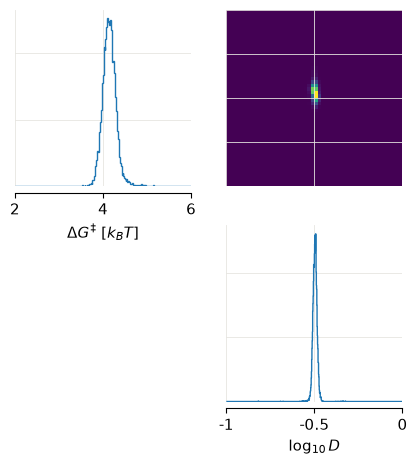

In [20]:
# 5. Inference: reduce the observation with your statistics, then sample the posterior
samples = posterior.sample((10_000,), x=summarize(my_summary, x_o))

pairplot(samples, limits=LIMITS, labels=LABELS, figsize=(5, 5));

In [21]:
check_blind(samples)

✅ PASS · Part 3 · blind trajectory · the 90% region contains the truth and covers 0.6% of the prior area (target < 5%)


**Why it works.** The reference statistics pin both parameters: the 90% region covers well under 1% of the prior area and contains the truth. The check has two halves on purpose.

- *Small alone is easy.* Train too long on too few simulations, or use too many statistics, and the posterior gets narrow and confidently wrong.
- *Containing the truth alone is easy too.* The prior contains the truth. So does the static-only posterior of Part 2, which covers about 7% of the prior area and fails the 5% target.

One caveat for the discussion: a calibrated 90% region misses the truth for one trajectory in ten. A single hit proves little; the coverage check of Notebook 1 is the real test. The score of Part 2 asks for the same two things, narrow and in the right place, of 200 trajectories at once and in one number.

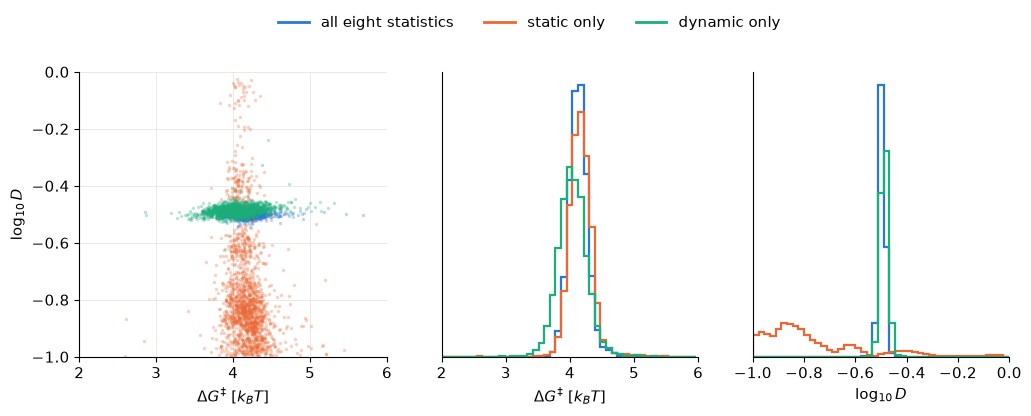

In [22]:
# What each group of statistics says about the blind trajectory
samples_static = posterior_static.sample((10_000,), x=summarize(summary_static, x_o), show_progress_bars=False)
samples_dynamic = posterior_dynamic.sample((10_000,), x=summarize(summary_dynamic, x_o), show_progress_bars=False)
plot_posteriors([samples, samples_static, samples_dynamic],
                ["all eight statistics", "static only", "dynamic only"], limits=LIMITS, axis_labels=LABELS);

The static posterior is a vertical band: it pins the barrier and leaves $D$ almost anywhere in the prior. (It leans towards small $D$. Part 4 explains why a histogram can do that.) The dynamic posterior is a flat ellipse: it pins $D$ and knows the barrier less well. Where the two overlap is the posterior of all eight statistics.

**Message of Part 3.** A good posterior is narrow and still contains the truth. Narrow alone is easy, and a narrow posterior that misses the truth is worse than a wide one.

## Part 4 · A posterior that is blind to D (15 min)

Now use the score helper as an instrument. Statistics decide what the posterior can know. So you can also decide what it cannot.

**Challenge.** Choose statistics so that the posterior learns $\Delta G^{\ddagger}$ and nothing about $D$.

**Passes when**, on the test set, the 90% interval of $\Delta G^{\ddagger}$ is narrower than 25% of the prior's, while the 90% interval of $\log_{10} D$ stays wider than 85% of the prior's.

**Then try the reverse:** statistics that give $D$ and nothing about $\Delta G^{\ddagger}$. There is no check for this one. How far do you get, and what stops you?

In [23]:
# The static statistics of Part 2 are all functions of the histogram of |x|: no time order involved.
summary_blind_to_D = summary_static

posterior_blind_to_D, _ = train_and_score(summary_blind_to_D, theta, x)
check_blind_to_D(posterior_blind_to_D, summary_blind_to_D)

score = 0.74   (4 statistics, 2,000 simulations, 79 epochs)
✅ PASS · Part 4 · blind to D · ΔG‡ interval is 13% of the prior's (target < 25%), log D interval is 95% (target > 85%)


In [24]:
# Why it works, in one line: shuffle the frames of a trajectory in time.
shuffled = np.random.default_rng(0).permuted(x[:5].numpy(), axis=1)
print("static statistics, original:\n", summary_static(x[:5].numpy()).round(3))
print("static statistics, frames shuffled in time:\n", summary_static(shuffled).round(3))
print("\ndynamic statistics, original:\n", summary_dynamic(x[:5].numpy()).round(3))
print("dynamic statistics, frames shuffled in time:\n", summary_dynamic(shuffled).round(3))

static statistics, original:
 [[0.035 0.984 0.265 0.575]
 [0.071 0.99  0.331 0.21 ]
 [0.052 0.992 0.302 0.321]
 [0.035 0.994 0.265 0.433]
 [0.034 0.995 0.262 0.491]]
static statistics, frames shuffled in time:
 [[0.035 0.984 0.265 0.575]
 [0.071 0.99  0.331 0.21 ]
 [0.052 0.992 0.302 0.321]
 [0.035 0.994 0.265 0.433]
 [0.034 0.995 0.262 0.491]]

dynamic statistics, original:
 [[ 0.282  0.464  0.975 15.   ]
 [ 0.16   0.397  0.74   7.   ]
 [ 0.268  0.516  1.073 18.   ]
 [ 0.309  0.507  1.014 20.   ]
 [ 0.253  0.408  0.776  6.   ]]
dynamic statistics, frames shuffled in time:
 [[1.381e+00 1.389e+00 1.384e+00 2.204e+03]
 [1.445e+00 1.433e+00 1.452e+00 2.177e+03]
 [1.409e+00 1.409e+00 1.420e+00 2.176e+03]
 [1.346e+00 1.339e+00 1.340e+00 2.052e+03]
 [1.463e+00 1.440e+00 1.450e+00 2.436e+03]]


**Why it works.** A statistic of the histogram does not change when the frames are shuffled in time. $D$ is a time scale: it only sets how fast the particle moves through the same landscape. In equilibrium the histogram is the Boltzmann distribution $e^{-G_0(x)}$, and $D$ does not appear in it. So for a long, well-equilibrated trajectory a posterior trained on histogram statistics cannot know $D$, however many simulations it sees.

These trajectories are finite, and that lets a little of $D$ through. Two details for the discussion.

- *Ignoring the time order is necessary, not sufficient.* The standard deviation of $x$ is a statistic of the histogram too, and it survives the shuffle. Still it knows about $D$: at a barrier of 6 $k_BT$ it falls from 0.90 to 0.43 as $D$ goes from 1 to 0.1, because a slow particle is still in the well it started in when the trajectory ends. The trajectory has not equilibrated, and how far it got depends on $D$. Statistics of $|x|$ remove this effect by symmetry: they do not care which well the particle is in. (The mean and standard deviation of $x$ also pin the barrier poorly, which is why the starting cell fails on the $\Delta G^{\ddagger}$ target.)
- *Even statistics of $|x|$ leak a little.* A slow particle collects fewer independent samples, so its histogram is noisier. With several static statistics the network can see how noisy the histogram is, and from that it learns a little about $D$: the interval shrinks to about 94% of the prior's. With a single static statistic it stays at 99%. That is why the target is 85% and not 100%.

score = 1.60   (1 statistics, 2,000 simulations, 81 epochs)
90% interval, as a fraction of the prior's: ΔG‡ 90%, log D 16%


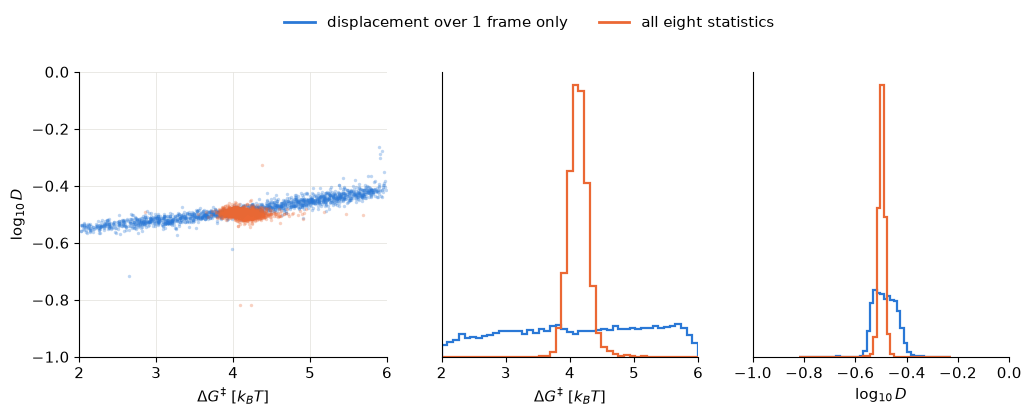

In [25]:
# The reverse: statistics that give D and nothing about the barrier height?
def summary_one_lag(x):
    return np.stack([(x[:, 1:] - x[:, :-1]).std(axis=1)], axis=1)        # displacement over 1 frame

posterior_one_lag, _ = train_and_score(summary_one_lag, theta, x)
width_dG, width_logD = posterior_widths(posterior_one_lag, summary_one_lag)

samples_one_lag = posterior_one_lag.sample((10_000,), x=summarize(summary_one_lag, x_o), show_progress_bars=False)
plot_posteriors([samples_one_lag, samples], ["displacement over 1 frame only", "all eight statistics"],
                limits=LIMITS, axis_labels=LABELS);

**The reverse works only halfway**, and the reason is physical. The cleanest candidate is the displacement over one frame. With this single statistic the posterior is blind to the barrier: its $\Delta G^{\ddagger}$ interval stays at about 90% of the prior's. But it narrows $D$ only to about 16% of its prior range, where the full set of statistics reaches 6%.

The band in the plot is tilted, and that is what stops it. For free diffusion the squared displacement would be $2D\tau$, a pure measure of $D$. But one frame lasts $\tau = 0.1$, and in that time the particle already feels the walls of its well: the well relaxes at the rate $4\Delta G^{\ddagger}D$, which is between 0.8 and 24 here. The same displacement can come from a slow particle in a wide well or a fast one in a narrow well. Pinning $D$ takes knowing the barrier.

So there is an asymmetry. The histogram is an equilibrium property, and equilibrium does not know time: static statistics of an equilibrated trajectory are blind to $D$, and they pin the barrier just as well without it. No such symmetry protects the dynamics from the potential: every dynamic statistic sees the forces. Only a much higher frame rate, $\tau \ll 1/(4\Delta G^{\ddagger}D)$, would let the short-time displacement measure $D$ alone.

**Message of Part 4.** The histogram is an equilibrium property, and equilibrium carries no time scale. No statistic of an equilibrium histogram can identify $D$. A finite trajectory lets a little of $D$ through, by how far its histogram has converged.

## Wrap-up

The hidden parameters of the blind trajectory, as promised:

Blind trajectory: ΔG‡ = 4.20 k_BT, D = 0.320 (log10 D = -0.495)


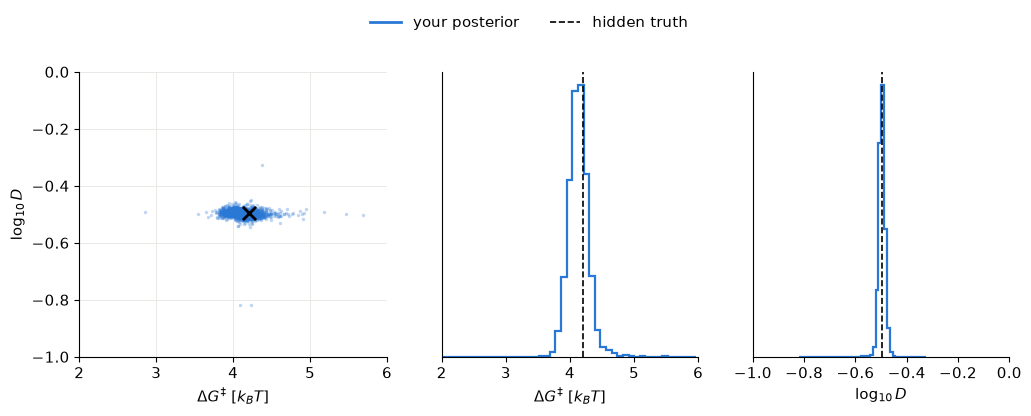

In [26]:
truth = tu.reveal_blind_truth()
plot_posteriors(samples, "your posterior", truth=truth, truth_label="hidden truth",
                limits=LIMITS, axis_labels=LABELS);

In [27]:
tu.scorecard()

Part 1 · by hand             ✅ PASS
Part 2 · summary statistics  ✅ PASS
Part 3 · blind trajectory    ✅ PASS
Part 4 · blind to D          ✅ PASS

4 of 4 checks passed.


**What you did.** The same five steps as in Notebook 1, on a time series: prior, simulator, training set, training, inference. The new step was yours: deciding what to measure. You judged the result by a score on held-out simulations, by whether the posterior contains the truth, and by how much it narrows the prior.

**Next steps for real data.**

- **A measurement model.** In a force-spectroscopy experiment you do not see the molecule. You see a bead attached to it by a flexible linker, and the bead has its own diffusion coefficient. Put the linker and the instrument noise into the simulator, and the same workflow infers the molecular parameters through them. This is the model of the lecture and of the [reference notebook](https://github.com/covinolab/sbi_for_smfe_tutorial).
- **Learned summaries.** Instead of inventing statistics, let an embedding network learn them from the raw trajectory together with the posterior (bonus 4 below). It needs more simulations and finds statistics nobody thought of.
- **Sequential rounds.** If you care about one observation only, simulate where its posterior is: train, sample parameters from the posterior of your observation, simulate there, retrain. Fewer simulations, at the price of a network that is good for this one observation only.
- **Checks without an answer key.** Coverage (Notebook 1, Part 4) and posterior predictive checks (bonus 1 below) work on any simulator.

---
## Bonus challenges

For those who finish early.

### Bonus 1 · Spot the wrong simulator

Three more blind trajectories. Two come from the simulator of this notebook. One comes from a **tilted** double well, a potential your simulator cannot produce. An SBI posterior will answer for all three without complaint.

Find the impostor with a **posterior predictive check**: for each trajectory, sample parameters from its posterior, simulate new trajectories with them, and compare those with the trajectory itself. If the model is right, the observation looks like one of its own predictions.

**Passes when** the check cell confirms your pick.

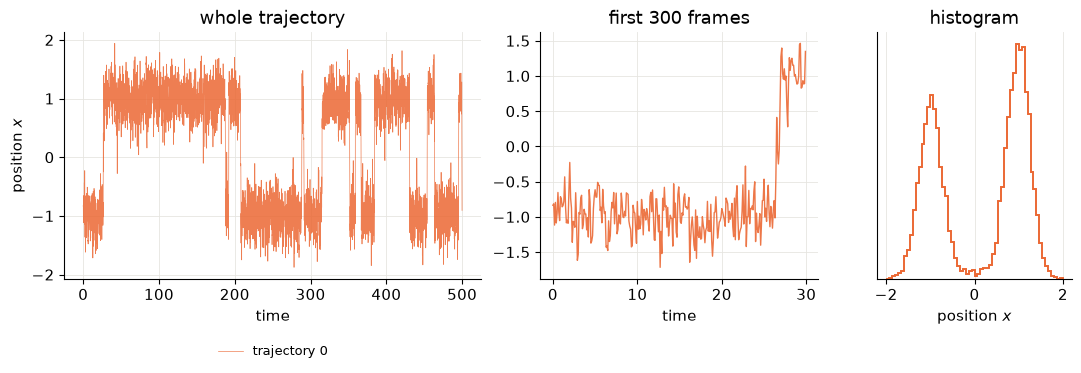

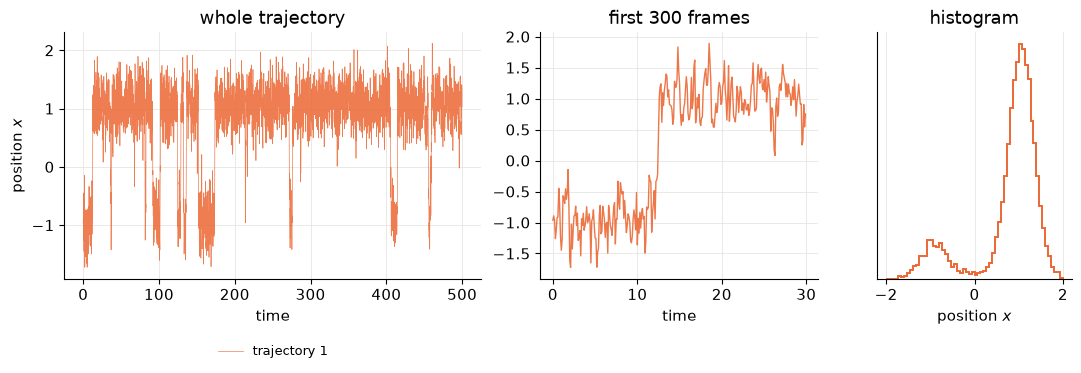

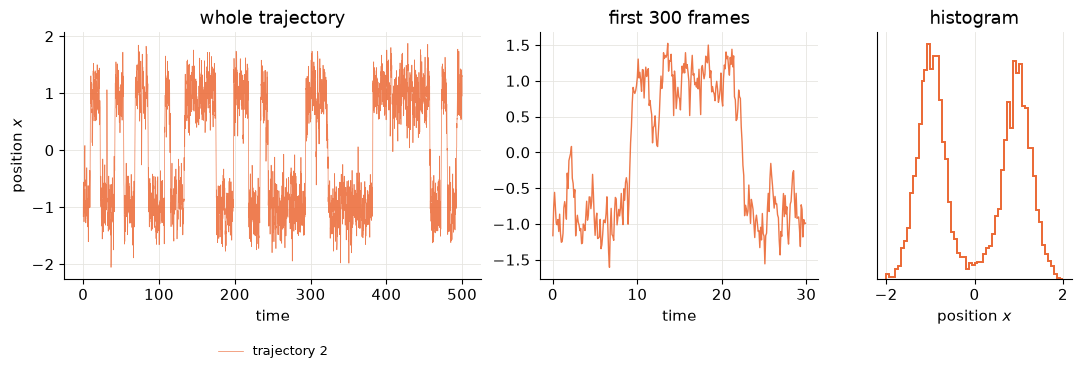

In [28]:
x_bonus = tu.load_trajectory("bonus")        # shape (3, 5000)
for i in range(3):
    plot_trajectories([x_bonus[i]], [f"trajectory {i}"])

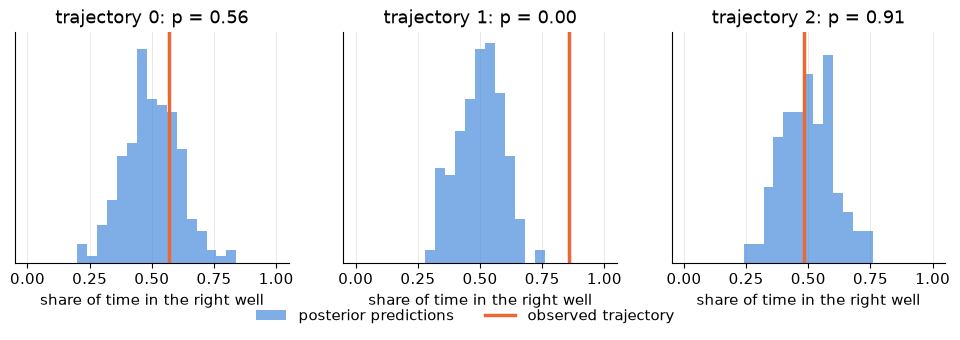

In [29]:
# For each trajectory: infer, simulate from the posterior, and compare one number that the
# symmetric double well makes a clear prediction about: the share of time spent in the right well.
def time_right(x):
    return (np.asarray(x) > 0).mean(axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
p_values = []
for i, ax in enumerate(axes):
    theta_post = posterior.sample((200,), x=summarize(my_summary, x_bonus[i]), show_progress_bars=False)
    x_predicted = simulator(theta_post, seed=i)                 # 200 trajectories the model predicts
    predicted, observed = time_right(x_predicted), time_right(x_bonus[i])
    tail = (predicted >= observed).mean()
    p_values.append(2 * min(tail, 1 - tail))                    # how extreme is the observation?
    ax.hist(predicted, bins=np.linspace(0, 1, 26), color=tu.C_YOURS, alpha=0.6, label="posterior predictions")
    ax.axvline(observed, color=tu.C_KEY, lw=2.5, label="observed trajectory")
    ax.set(xlabel="share of time in the right well", title=f"trajectory {i}: p = {p_values[-1]:.2f}", yticks=[])
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.14));

In [30]:
pick = int(np.argmin(p_values))
tu.check_wrong_simulator(pick)

✅ PASS · Bonus · wrong simulator · that one is from the tilted well


**Why it works.** The posterior answers a conditional question: *if* the data came from this simulator, which parameters fit? It has no way to say "none". For the tilted trajectory it returns a narrow, confident posterior like for the other two.

The posterior predictive check asks the question the posterior cannot: do simulations from the inferred parameters look like the observation? The symmetric double well predicts that a trajectory with this many hops spends about half its time in each well, give or take 15 points. Trajectory 1 spends 86% of its time on the right, further out than any of 200 predictions. In its potential the right well is lower by 1.5 $k_BT$.

Which statistic to compare is a choice, and a good check uses one the network was *not* trained on. All eight reference statistics are symmetric under $x \to -x$, so the posterior never looked at the asymmetry. That is exactly why it could be fooled, and why the asymmetry exposes it.

### Bonus 2 · Sparse training data

Simulations are often expensive. Cut the training set from 2,000 simulations to 200, `theta[:200]` and `x[:200]`, and watch the score drop. Then win it back with those 200 simulations: change the statistics, the network (`density_estimator=`) or the training (any argument of sbi's `.train()`, for example `training_batch_size=`).

**Passes when**, with 200 simulations, you are back above bronze and have won back at least half of what the cut cost you.

In [31]:
theta_200, x_200 = theta[:200], x[:200]

print("the reference statistics, trained as before:")
_, score_200_start = train_and_score(my_summary, theta_200, x_200)

print("\nthe same, with a batch size of 20 instead of 200:")
_, score_200_batches = train_and_score(my_summary, theta_200, x_200, training_batch_size=20)

# Fewer statistics, each one already close to a parameter (see "One way to gold"),
# and a simpler density estimator: a mixture of Gaussians instead of a flow.
def summary_four(x):
    return summary_gold(x)[:, :4]

print("\nfour statistics that estimate the parameters, a mixture density network, batch size 20:")
_, score_200 = train_and_score(summary_four, theta_200, x_200, density_estimator="mdn", training_batch_size=20)

tu.check_sparse(score_200, score_200_start=score_200_start, score_2000=score)

the reference statistics, trained as before:
score = 1.68   (8 statistics, 200 simulations, 135 epochs)

the same, with a batch size of 20 instead of 200:
score = 2.53   (8 statistics, 200 simulations, 69 epochs)

four statistics that estimate the parameters, a mixture density network, batch size 20:
score = 2.98   (4 statistics, 200 simulations, 51 epochs)
✅ PASS · Bonus · sparse training data · score 2.98 with 200 simulations: 70% of the drop from 3.54 to 1.68 won back (target: at least 50%, and above bronze, -1.08)


**Why it works.** With ten times fewer simulations the reference solution falls from about 3.5 to about 1.6. Three changes win most of it back, to about 2.9.

- *Smaller batches.* With 200 simulations and a batch size of 200, one epoch is a single gradient step, and the early stopping watches a validation set of 20 trajectories. Training stops after a few dozen steps. A batch size of 20 gives ten times as many steps per epoch. This alone is worth about one unit of score.
- *Fewer, better statistics.* Every input dimension has to be learned from the same 200 examples. Four statistics that are already estimates of the parameters leave the network little to learn.
- *A simpler density estimator.* A mixture of Gaussians has fewer ways to overfit 200 examples than a flow, and its score is more stable from seed to seed.

The remaining gap to 3.5 is the price of 1,800 simulations. The lesson for expensive simulators: the fewer simulations you have, the more of the work your statistics have to do.

### Bonus 3 · An ensemble of posteriors

Train five networks on the same 200 simulations, each with a different `seed`, and combine them with `EnsemblePosterior` from `sbi.inference`. There is no score here: look at what happens to the posterior of the blind trajectory when the ensemble replaces a single network.

score = 1.68   (8 statistics, 200 simulations, 135 epochs)
score = 1.27   (8 statistics, 200 simulations, 104 epochs)
score = 2.04   (8 statistics, 200 simulations, 179 epochs)
score = 1.79   (8 statistics, 200 simulations, 158 epochs)
score = 1.88   (8 statistics, 200 simulations, 147 epochs)


  0%|          | 0/989 [00:00<?, ?it/s]

  0%|          | 0/1024 [00:00<?, ?it/s]

  0%|          | 0/980 [00:00<?, ?it/s]

  0%|          | 0/996 [00:00<?, ?it/s]

  0%|          | 0/1011 [00:00<?, ?it/s]

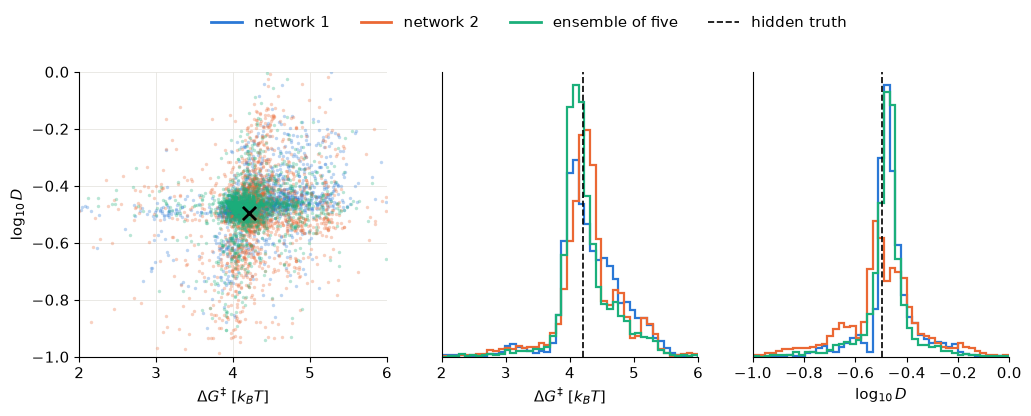

In [32]:
from sbi.inference import EnsemblePosterior

# Five networks on the same 200 simulations: only the random initialisation differs
members, member_scores = zip(*[train_and_score(my_summary, theta_200, x_200, seed=seed) for seed in range(5)])
ensemble = EnsemblePosterior(list(members))

s_o = summarize(my_summary, x_o)
samples_members = [m.sample((5000,), x=s_o, show_progress_bars=False) for m in members[:2]]
samples_ensemble = ensemble.sample((5000,), x=s_o)

plot_posteriors(samples_members + [samples_ensemble], ["network 1", "network 2", "ensemble of five"],
                truth=truth, truth_label="hidden truth", limits=LIMITS, axis_labels=LABELS);

In [33]:
# Not asked for, but telling: the score of the ensemble. Its density is the average of the five densities.
theta_test, x_test = tu.load_test_set()
s_test = summarize(my_summary, x_test)
log_probs = torch.stack([m.log_prob_batched(theta_test[None], x=s_test, norm_posterior=False)[0]
                         for m in members])                                  # shape (5, 200)
score_ensemble = (torch.logsumexp(log_probs, dim=0) - np.log(len(members))).mean().item()
print("single networks:", ", ".join(f"{score:.2f}" for score in member_scores))
print(f"ensemble of five: {score_ensemble:.2f}")

single networks: 1.68, 1.27, 2.04, 1.79, 1.88
ensemble of five: 2.14


**What happens.** Five networks trained on the same 200 simulations, differing only in their random initialisation, give five different posteriors for the same trajectory: different centres, different tails. Each of them alone is a confident answer. Their disagreement shows that 200 simulations do not determine the network.

The ensemble is the equal-weight mixture of the five. Where the members agree, it stays sharp. Where a single member puts probability that the others do not, that probability is divided by five. So the ensemble keeps the common core and thins out the idiosyncratic tails of each member.

On the test set the ensemble scores higher than every one of its members. That it cannot score lower than their average is a mathematical fact (the logarithm of an average is at least the average of the logarithms). That it beats the best one is the gain from averaging out five different overfits.

An ensemble does not add information about the simulator. It averages over what the training did not pin down. That is cheap here: the simulations are shared, only the training is repeated.

### Bonus 4 · Learned summaries

Let a network invent the statistics. `CNNEmbedding` in `sbi.neural_nets.embedding_nets` is a 1D convolutional network that takes the raw trajectory and returns a summary vector; `posterior_nn(model="nsf", embedding_net=...)` puts it in front of the density estimator, and the two are trained together.

Beat your own score with a learned embedding. This one is open-ended and hard: with 2,000 simulations a CNN stays far below good hand-made statistics, so simulate more. Training takes minutes, not seconds.

In [34]:
from sbi.neural_nets import posterior_nn
from sbi.neural_nets.embedding_nets import CNNEmbedding

RUN_SLOW_BONUS = True        # about 4 minutes on two CPU cores; set to False to skip

def cnn_estimator():
    """Four convolution layers shrink the 5,000 frames to a few hundred numbers, two dense layers to 16."""
    embedding_net = CNNEmbedding(input_shape=(5000,), num_conv_layers=4, out_channels_per_layer=[8, 16, 32, 32],
                                 kernel_size=7, pool_kernel_size=4, num_linear_units=64, output_dim=16)
    return posterior_nn("nsf", num_transforms=2, embedding_net=embedding_net, z_score_x="none")

def raw_trajectory(x):
    return x           # no statistics: the network sees all 5,000 frames

if RUN_SLOW_BONUS:
    posterior_cnn, score_cnn = train_and_score(raw_trajectory, theta, x, density_estimator=cnn_estimator())

score = 1.86   (5000 statistics, 2,000 simulations, 158 epochs)


**What we found.** The cell above trains the deeper CNN on the 2,000 simulations of this notebook. The other rows are from our own runs.

| Summaries | Simulations | Score |
| --- | --- | --- |
| sbi's default `CNNEmbedding` (two convolution layers) | 2,000 | 0.4 to 0.9 |
| the deeper CNN above | 2,000 | 1.5 to 1.9 |
| the deeper CNN above | 10,000 | 3.1 |
| our eight hand-made statistics | 2,000 | 3.5 |
| our eight hand-made statistics | 10,000 | 3.75 |

We did not beat the hand-made statistics with a CNN. With 2,000 simulations it is not close, and with five times as many it is still behind what eight numbers achieve with 2,000. The 10,000-simulation run took ten minutes on four CPU cores.

**Why.** The CNN has to discover from examples what you put in by hand: that the sign of $x$ does not matter, that wells have a width, that hops can be counted, that displacements at short lags measure $D$. Each of these is a few lines of NumPy and thousands of simulations to learn. Hand-made statistics are prior knowledge about the physics, and prior knowledge is worth simulations.

Learned summaries win where that knowledge runs out: when nobody knows which features of the data matter, or when the features are too many and too subtle to write down. They also remove the risk of Part 4, where a badly chosen set of statistics silently made the posterior blind to a parameter. The usual practice is to start with statistics you understand, and move to a learned embedding once simulations are cheap enough to pay for it.